In [123]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,id,FruitMass,FruitSet,SeedCount,CloneSize,HoneyBeeDensity,BumbleDensity,AndrenaDensity,OsmiaDensity,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,RaspberryYield
0,1,0.464,0.533,39,12.5,0.25,0.25,0.75,0.75,86.0,52.0,71.9,62.0,30.0,50.8,24.0,0.39,7007
1,2,0.431,0.482,35,25.0,0.50,0.38,0.38,0.63,69.7,42.1,58.2,50.2,24.3,41.2,34.0,0.56,5596
2,3,0.476,0.568,40,12.5,0.25,0.25,0.38,0.75,94.6,57.2,79.0,68.2,33.0,55.9,16.0,0.26,6941
3,4,0.441,0.548,39,25.0,0.50,0.25,0.63,0.50,69.7,42.1,58.2,50.2,24.3,41.2,24.0,0.39,7127
4,5,0.434,0.469,34,25.0,0.50,0.38,0.38,0.63,77.4,46.8,64.7,55.8,27.0,45.8,34.0,0.56,5330


In [124]:
suma = 0    

for _, row in df_test.iterrows():
    if row.HoneyBeeDensity == 0.25 and row.BumbleDensity == 0.25 and row.AndrenaDensity == 0.25 and row.OsmiaDensity == 0.25:
        if row.FruitMass >= 0.45 and row.SeedCount >= 36:
            suma += 1

df_1 = pd.DataFrame({
    "datapointID": [0],
    "subtaskID": 1,
    "answer": int(suma)
})

df_1

,datapointID,subtaskID,answer
0,0,1,31


In [125]:
suma = 0
cnt = 0

for _, row in df_test.iterrows():
    if row.RainingDays < 20 and row.FruitMass > 0.45 and row.CloneSize == 25.0:
            suma += row.SeedCount
            cnt += 1

df_2 = pd.DataFrame({
    "datapointID": [1],
    "subtaskID": 2,
    "answer": int(suma / cnt)
})

df_2

,datapointID,subtaskID,answer
0,1,2,38


In [126]:
features = [col for col in df_test.columns if col != 'id']
target = 'RaspberryYield'

X = df_train[features]
y = df_train[target]
X_final = df_test[features]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns = features)
X_final = pd.DataFrame(scaler.transform(X_final), columns = features)

import numpy as np
X.HoneyBeeDensity = np.log(X.HoneyBeeDensity+2)
X_final.HoneyBeeDensity = np.log(X_final.HoneyBeeDensity+2)

X.head()

,FruitMass,FruitSet,SeedCount,CloneSize,HoneyBeeDensity,BumbleDensity,AndrenaDensity,OsmiaDensity,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays
0,0.463814,0.402913,0.689898,-1.076135,0.524224,-0.603182,1.717919,1.124083,0.415249,0.415558,0.421132,0.415934,0.415896,0.410638,0.463103,0.407024
1,-0.425382,-0.282819,-0.299963,0.814190,0.805116,1.553757,-0.775645,0.266654,-1.368325,-1.371084,-1.373268,-1.370787,-1.369507,-1.371874,1.320414,1.443839
2,0.787158,0.873513,0.937364,-1.076135,0.524224,-0.603182,-0.775645,1.124083,1.356276,1.353996,1.351076,1.354719,1.355582,1.357598,-0.222747,-0.385835
3,-0.155929,0.604599,0.689898,0.814190,0.805116,-0.603182,0.909196,-0.662227,-1.368325,-1.371084,-1.373268,-1.370787,-1.369507,-1.371874,0.463103,0.407024
4,-0.344546,-0.457614,-0.547429,0.814190,0.805116,1.553757,-0.775645,0.266654,-0.525778,-0.522880,-0.521910,-0.522852,-0.523790,-0.517753,1.320414,1.443839


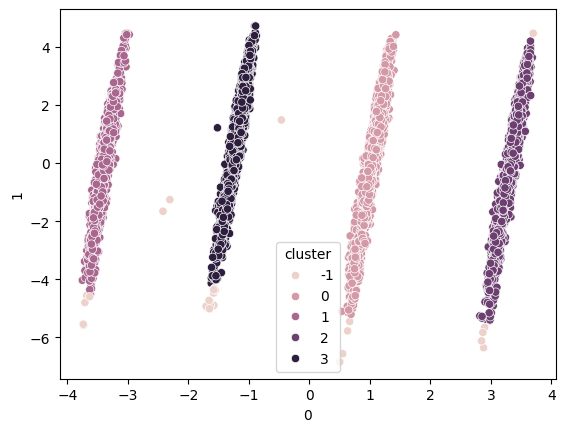

In [127]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN

pca = PCA(n_components=2)
X_red = pd.DataFrame(pca.fit_transform(X))
X_red_final = pd.DataFrame(pca.transform(X_final))

db = DBSCAN(min_samples=25)
X["cluster"] = db.fit_predict(X_red)
X_final["cluster"] = db.fit_predict(X_red_final)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=X["cluster"])
plt.show()

In [128]:
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score

model = CatBoostRegressor(silent=True, depth=4, n_estimators=450)

cross_val_score(model, X, y, cv=3, scoring='neg_mean_absolute_error').mean()

-355.57102939005745

In [129]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [130]:
df_3 = pd.DataFrame({
    "datapointID": df_test.id,
    "subtaskID": 3,
    "answer": y_preds
})

df_3.head()

,datapointID,subtaskID,answer
0,2,3,5812.318034
1,3,3,6423.904215
2,4,3,6206.990504
3,5,3,5783.288591
4,6,3,7123.850154


In [131]:
model2 = LinearRegression()
model2.fit(X, y)
fake_preds = model2.predict(X_final)

In [132]:
suma = 0
cnt = 0

for i, row in df_test.iterrows():
    if row.AverageRainingDays > 0.3 and (row.SeedCount > 42 or row.SeedCount < 28):
            suma += fake_preds[i]
            cnt += 1

df_4 = pd.DataFrame({
    "datapointID": [3002],
    "subtaskID": 4,
    "answer": suma / cnt
})

df_4

,datapointID,subtaskID,answer
0,3002,4,5346.888263


In [133]:
submission = pd.concat([df_1, df_2, df_3, df_4])
submission.answer = submission.answer.apply(lambda x: int(x))
submission.to_csv("submission.csv", index=False)

In [134]:
submission

,datapointID,subtaskID,answer
0,0,1,31
0,1,2,38
0,2,3,5812
1,3,3,6423
2,4,3,6206
...,...,...,...
2996,2998,3,6502
2997,2999,3,4693
2998,3000,3,6302
2999,3001,3,6603
